# Pessoa 2 — Análise Exploratória (EDA) e Estatística

**Pergunta:** quais condições elevam o risco de um acidente em rodovia federal ser **fatal**?

Este notebook é a **vitrine** da análise: todo o cálculo mora em `src/p2_eda/` (testado em `tests/test_eda_p2.py`) e aqui só chamamos as funções e olhamos os resultados. Para regenerar figuras, tabelas e textos de uma vez: `python -m src.p2_eda.executar_eda`.

Roteiro: **1** descrever → **2** quando → **3** onde → **4** quem/por quê → **5** numéricas → **6** causa raiz × confusão → **7** veredito → **8** insumos para a modelagem.

In [1]:
import sys, pathlib
RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
from IPython.display import Image, display
from src.p2_eda import analises as an, configuracao as cfg
from src.p2_eda.executar_eda import calcular_tabelas

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
df = an.carregar_base(RAIZ / "data/processed/acidentes_prf_modelagem.csv")
t = calcular_tabelas(df)
FIG = RAIZ / "reports/figuras"
df.shape

(145342, 42)

## 1. Visão geral e descritiva
Taxa de letalidade com IC de Wilson, por ano (os dois anos servem de réplica um do outro).

In [2]:
t["p2_resumo_geral"].round(3)

,recorte,n,n_fatais,taxa_pct,ic_inf_pct,ic_sup_pct
0,Total,145342,10240,7.045,6.915,7.178
1,2024,73006,5136,7.035,6.852,7.223
2,2025,72336,5104,7.056,6.872,7.245


Numéricas: todas assimétricas e não normais → mediana/IQR na descrição, Mann-Whitney na inferência.

In [3]:
t["p2_descritiva_numericas"].set_index("variavel")[["media","mediana","desvio_padrao","iqr","assimetria","pct_nulos","mediana_fatal","mediana_nao_fatal"]].round(2)

,media,mediana,desvio_padrao,iqr,assimetria,pct_nulos,mediana_fatal,mediana_nao_fatal
variavel,,,,,,,,
km,258.59,191.0,227.51,331.6,1.01,0.00,215.25,189.00
veiculos,1.99,2.0,1.10,1.0,5.36,0.00,2.00,2.00
idade_media_condutores,40.52,40.0,11.55,16.0,0.43,4.82,41.50,39.67
pct_condutores_homens,88.25,100.0,27.45,0.0,-2.29,3.47,100.00,100.00
idade_media_veiculos,10.87,10.0,7.00,9.0,1.10,3.82,11.00,10.00


## 2. Quando
O volume é máximo às 18h, mas a letalidade é máxima de madrugada (a "tesoura").

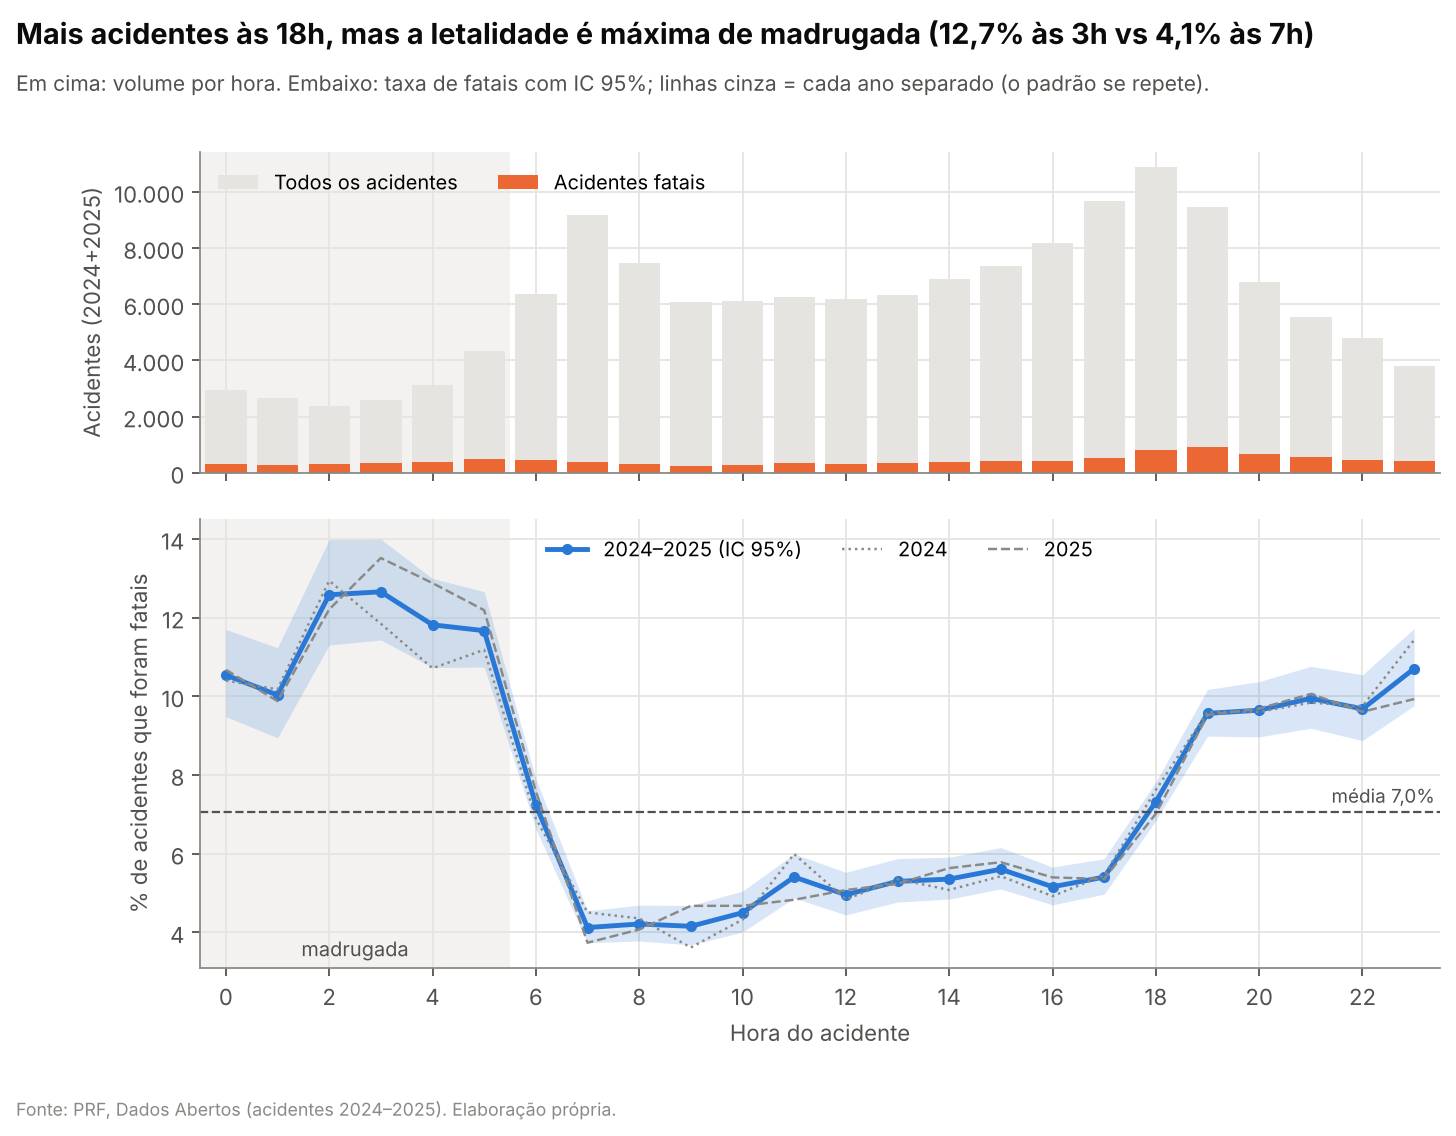

In [4]:
display(Image(FIG / "p2_fig2_hora_do_dia.png", width=900))

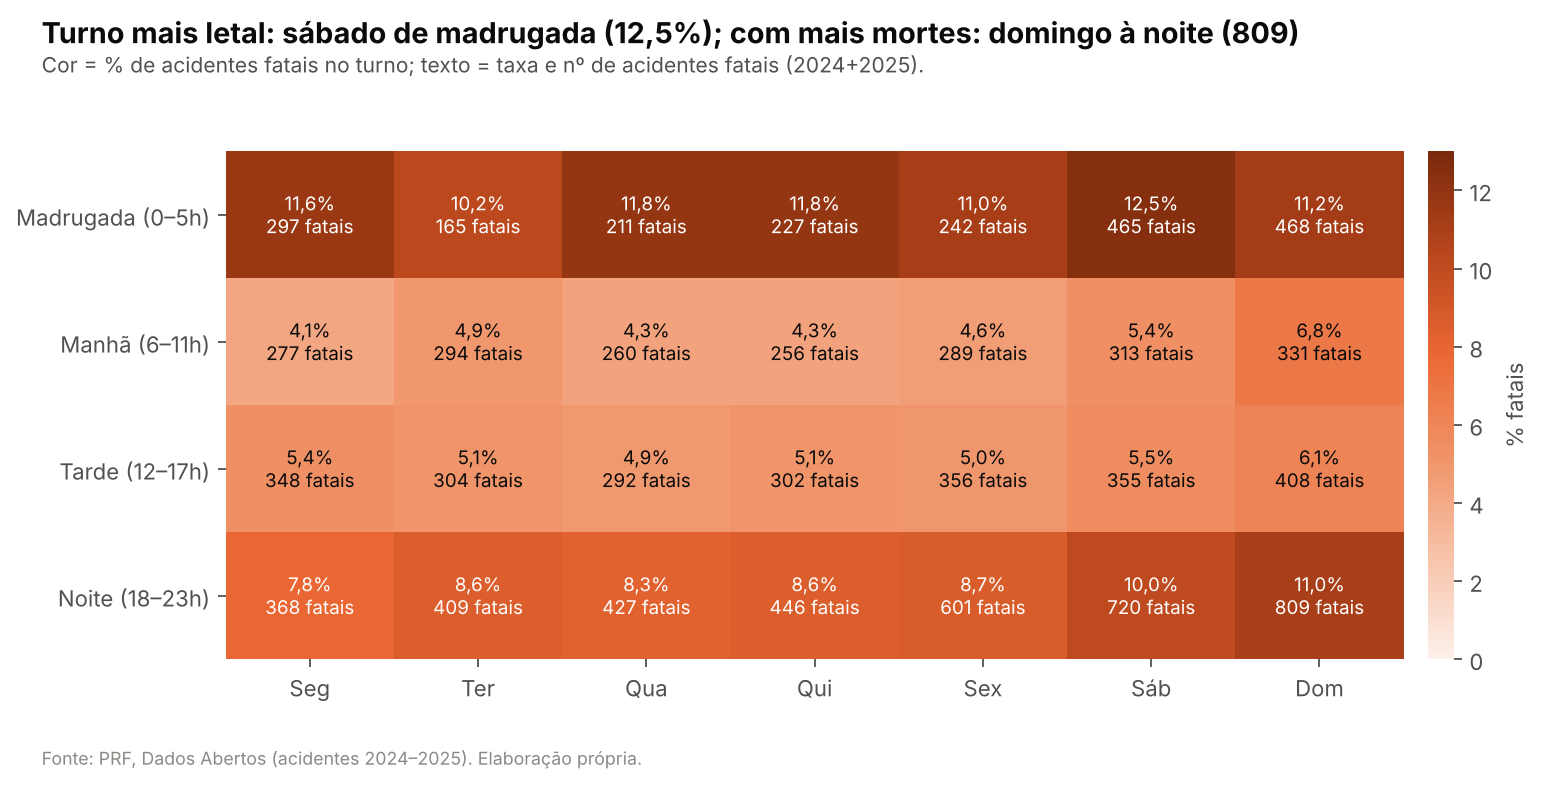

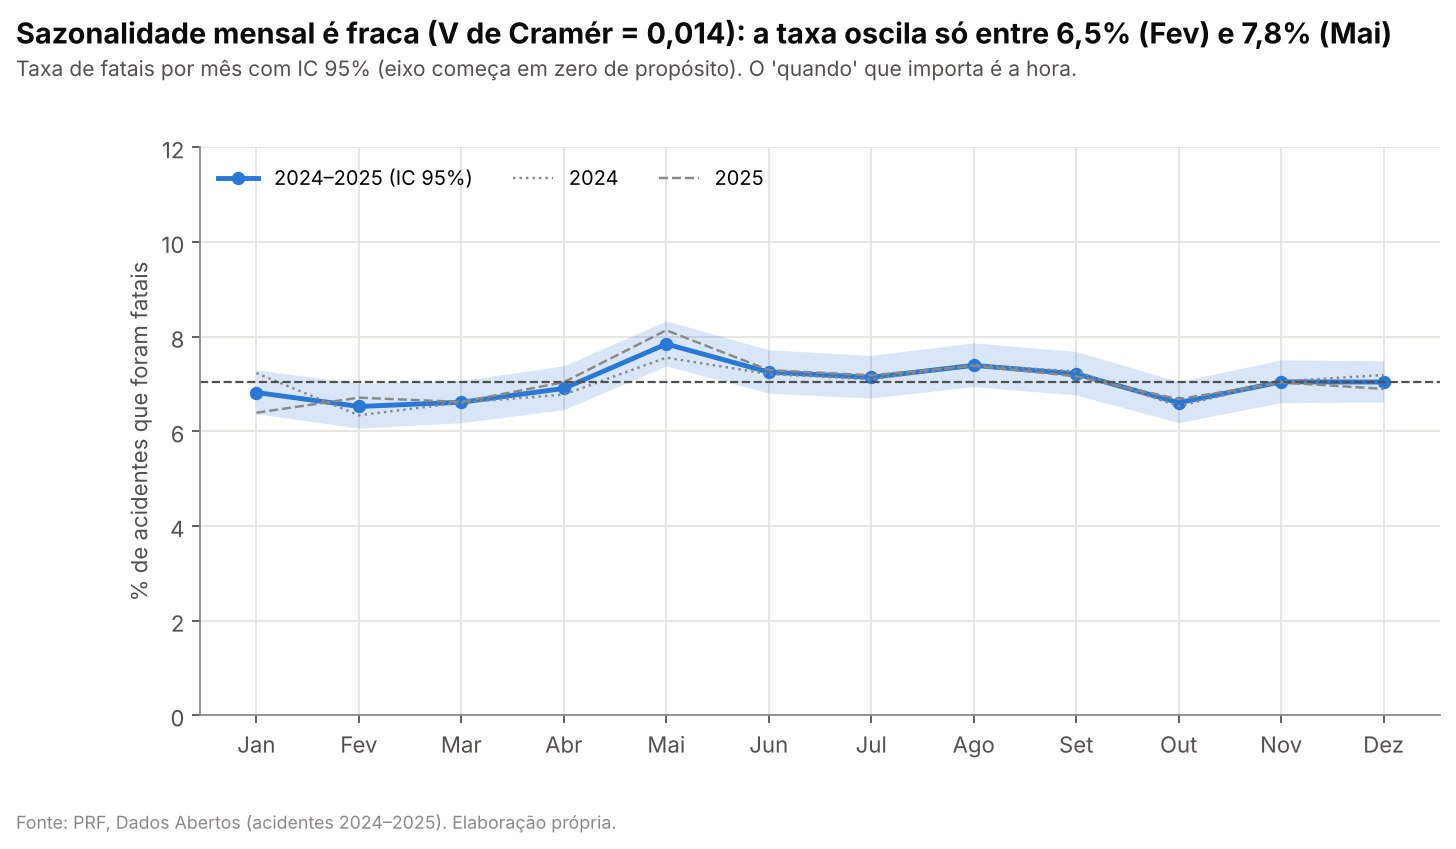

In [5]:
display(Image(FIG / "p2_fig6_semana_x_faixa_horaria.png", width=900))
display(Image(FIG / "p2_fig5_sazonalidade_mensal.png", width=900))

## 3 e 4. Onde, quem e por quê — fatores de risco
Risco relativo com IC 95%, p-valor corrigido por Holm e réplica em 2024 e 2025.

In [6]:
t["p2_fatores_risco"][["hipotese","fator","taxa_expostos_pct","taxa_referencia_pct","rr","rr_ic_inf","rr_ic_sup","rr_2024","rr_2025","p_holm","replica_nos_dois_anos","pct_dos_fatais_expostos"]].sort_values("rr", ascending=False).round(3)

,hipotese,fator,taxa_expostos_pct,taxa_referencia_pct,rr,rr_ic_inf,rr_ic_sup,rr_2024,rr_2025,p_holm,replica_nos_dois_anos,pct_dos_fatais_expostos
0,H3,Pedestre envolvido,28.038,6.117,4.584,4.382,4.795,4.678,4.488,0.00,True,16.855
1,H3,Caminhão envolvido,12.279,5.265,2.332,2.247,2.421,2.326,2.339,0.00,True,44.248
5,H2,Pista simples (vs. dupla/múltipla),9.770,4.524,2.160,2.075,2.247,2.213,2.108,0.00,True,66.650
6,H2,Trecho rural (vs. urbano),9.012,4.430,2.035,1.950,2.123,2.058,2.011,0.00,True,73.018
7,H1,Madrugada ou noite (vs. 6h-17h),9.876,5.095,1.938,1.866,2.013,1.950,1.926,0.00,True,57.178
8,H4,Norte ou Nordeste (vs. Sul/Sudeste),10.431,5.476,1.905,1.831,1.982,1.900,1.909,0.00,True,40.986
2,H3,Bicicleta envolvida,12.429,6.913,1.798,1.643,1.967,1.602,2.009,0.00,True,4.248
3,H3,Ônibus envolvido,11.621,6.905,1.683,1.547,1.831,1.599,1.771,0.00,True,4.922
9,H5,Fim de semana,8.358,6.432,1.299,1.251,1.350,1.283,1.316,0.00,True,37.783
11,H2,Curva (vs. sem curva),8.242,6.776,1.216,1.163,1.273,1.177,1.257,0.00,True,21.504


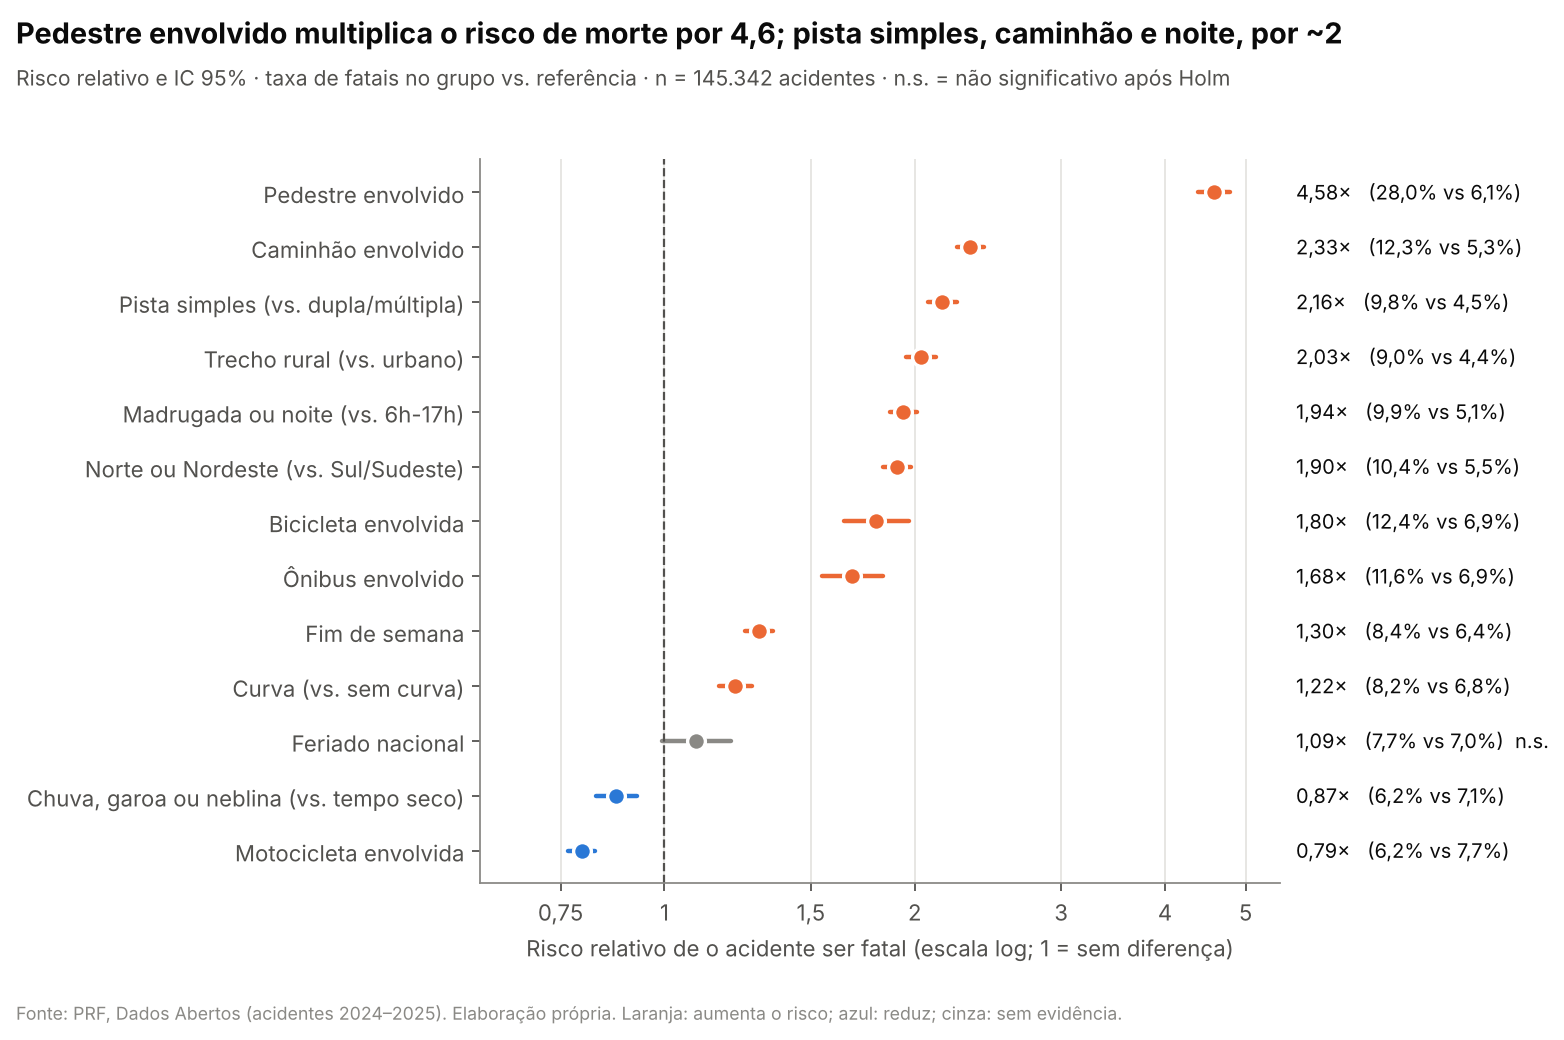

In [7]:
display(Image(FIG / "p2_fig1_risco_relativo.png", width=900))

Mecanismo da pista simples: a colisão frontal (sem barreira central).

In [8]:
tap = t["p2_tipo_acidente_por_pista"]
tap[tap["tipo_acidente"] == "Colisão frontal"][["tipo_pista","n","taxa_pct","pct_dos_acidentes","pct_dos_fatais"]].round(2)

,tipo_pista,n,taxa_pct,pct_dos_acidentes,pct_dos_fatais
7,Dupla,799,14.52,0.55,1.13
23,Múltipla,222,9.46,0.15,0.21
32,Simples,8504,31.37,5.85,26.05


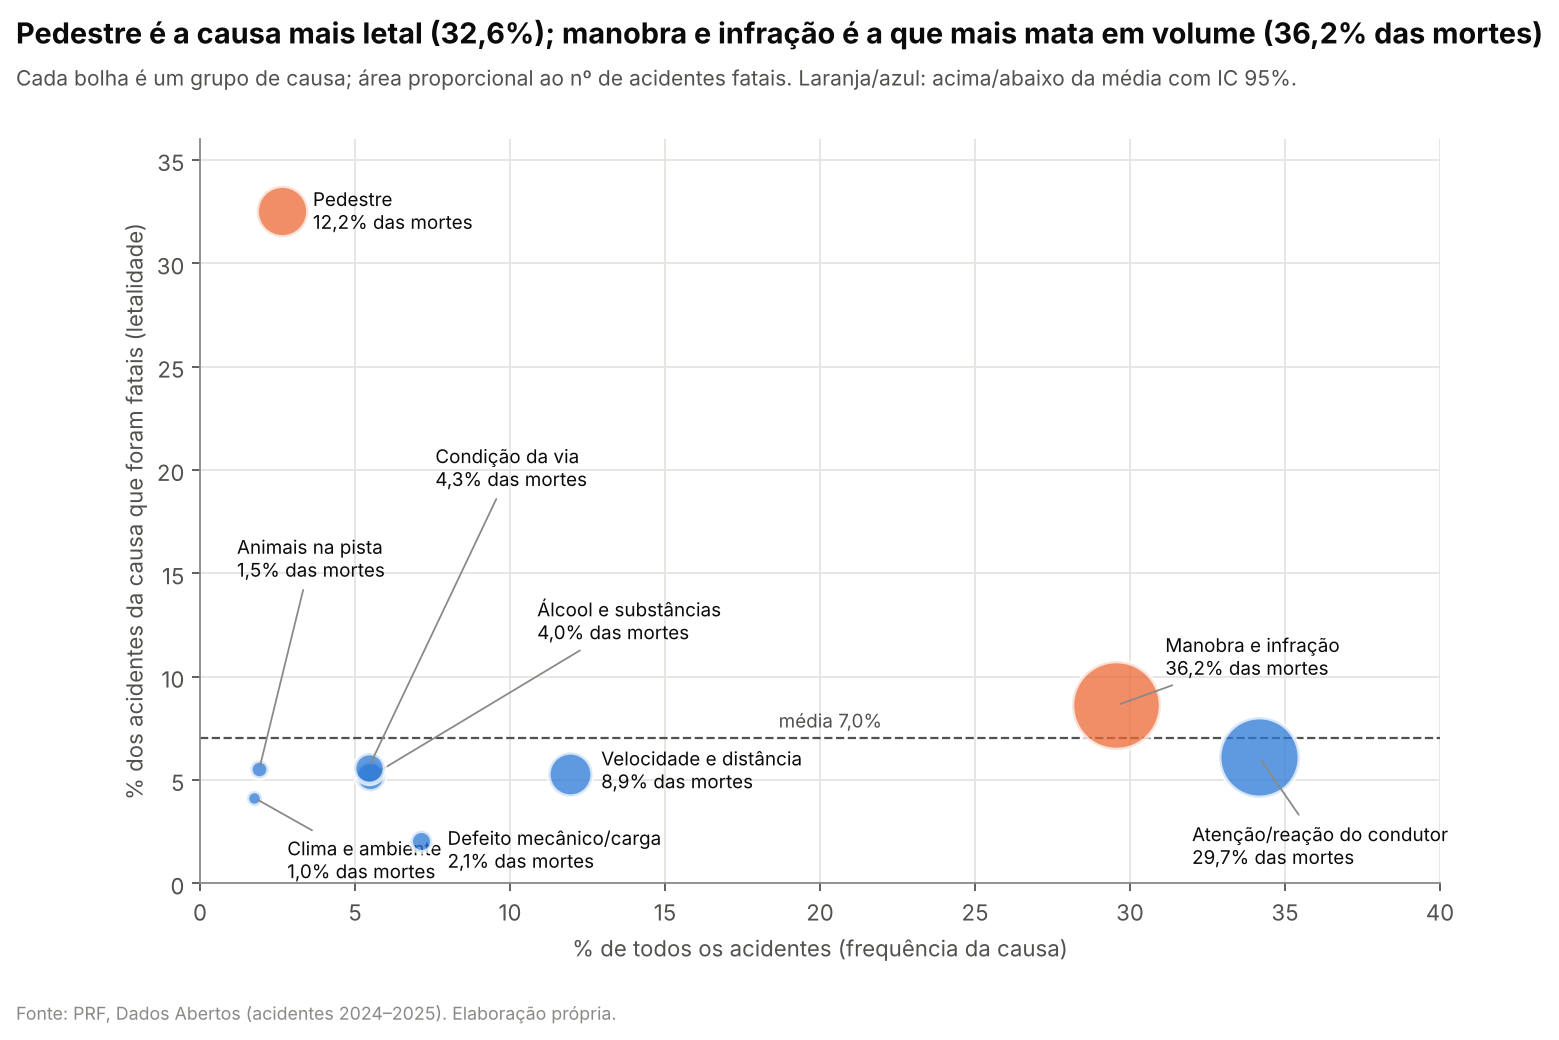

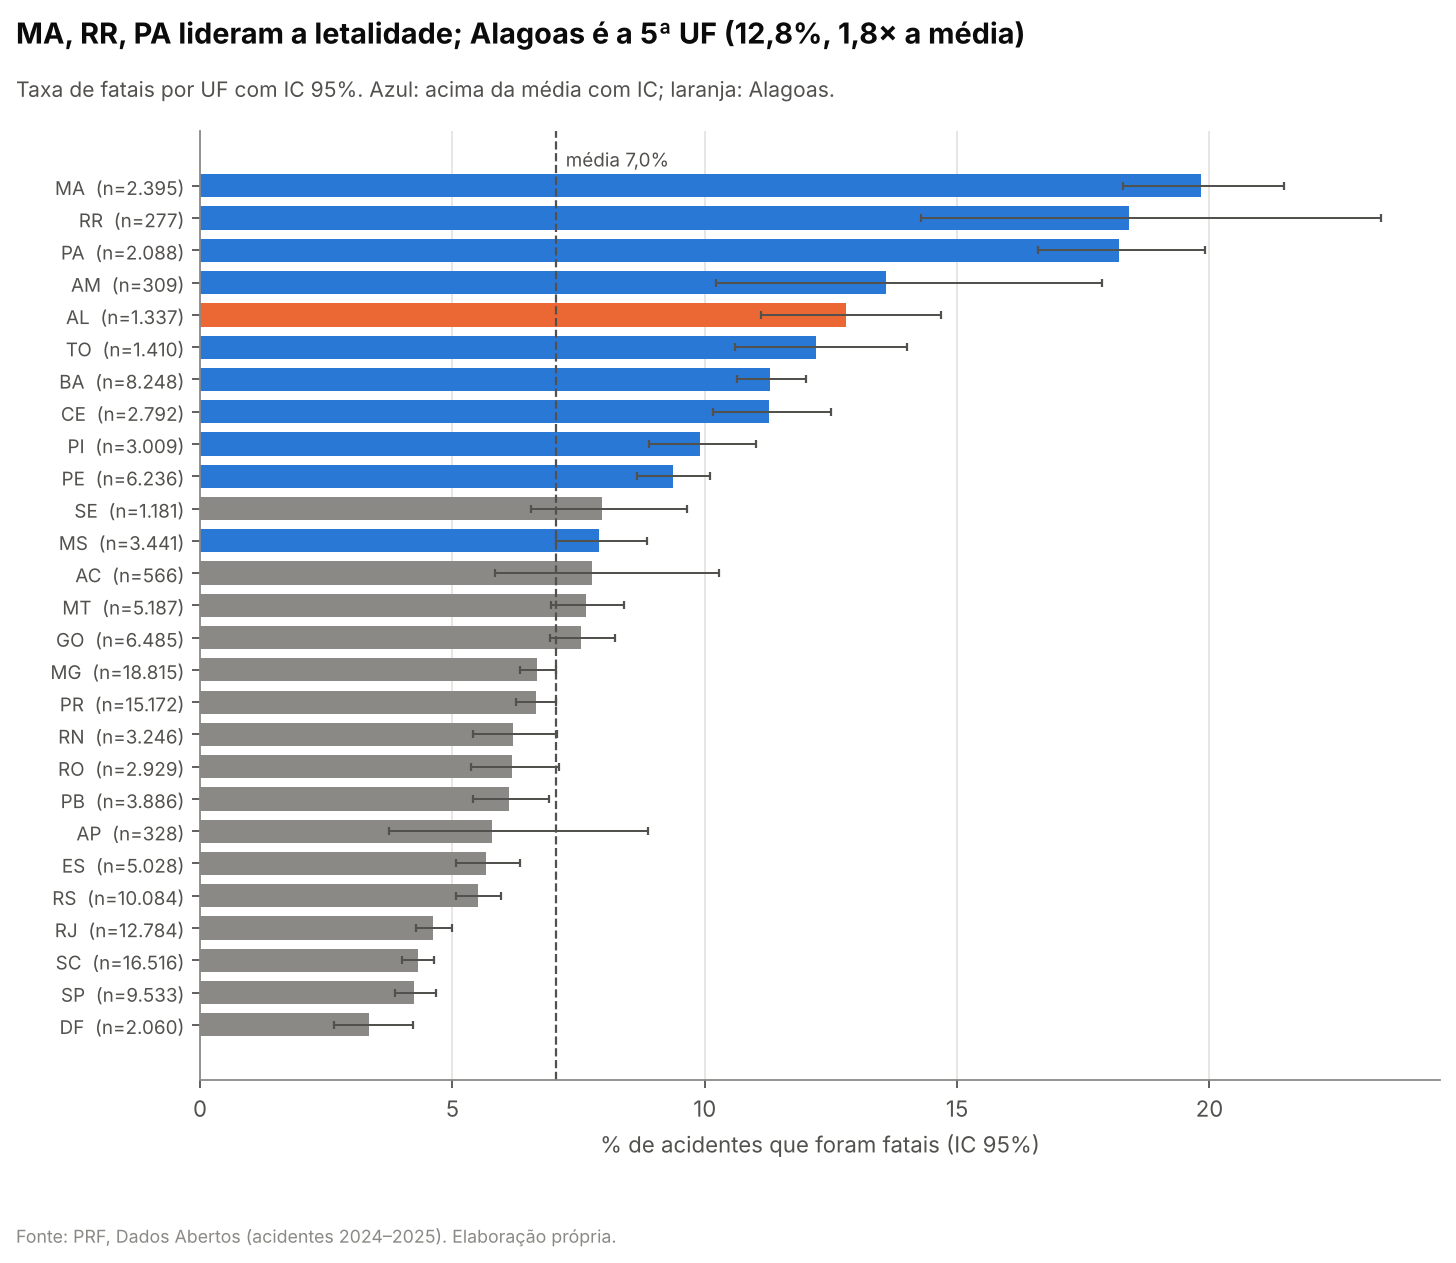

In [9]:
display(Image(FIG / "p2_fig3_volume_vs_gravidade_causas.png", width=900))
display(Image(FIG / "p2_fig7_taxa_por_uf.png", width=750))

Qui-quadrado de independência + V de Cramér (o V compara variáveis entre si; o RR mede a importância prática).

In [10]:
t["p2_testes_qui_quadrado"][["hipotese","variavel","n_categorias","qui2","gl","v_cramer","magnitude","p_holm","grupo_maior_taxa","maior_taxa_pct"]].round(4)

,hipotese,variavel,n_categorias,qui2,gl,v_cramer,magnitude,p_holm,grupo_maior_taxa,maior_taxa_pct
0,H1,faixa_horaria,4,1338.9380,3,0.0960,desprezível,0.0000,Madrugada,11.5284
1,H1,dia_semana,7,190.0816,6,0.0362,desprezível,0.0000,domingo,8.7122
2,H2,tipo_pista,3,1538.1922,2,0.1029,pequeno,0.0000,Simples,9.7700
3,H4,regiao,5,1045.1852,4,0.0848,desprezível,0.0000,Norte,11.2432
4,H4,uf,27,2129.8550,26,0.1211,pequeno,0.0000,MA,19.8330
5,H6,condicao_metereologica,8,143.1915,7,0.0314,desprezível,0.0000,Nao_informado,10.7254
6,H7,grupo_causa,9,4621.1981,8,0.1783,pequeno,0.0000,Pedestre,32.5600
7,H7,tipo_acidente,16,13530.2853,15,0.3051,médio,0.0000,Colisão frontal,29.4488
8,H9,mes,12,28.4205,11,0.0140,desprezível,0.0056,5.0,7.8479


## 5. Numéricas: fatais × não fatais

,variavel,mediana_fatal,mediana_nao_fatal,r_rank_bisserial,magnitude,p_holm
0,veiculos,2.0,2.000,0.260,pequeno,0.0
1,idade_media_condutores,41.5,39.667,0.092,desprezível,0.0
2,idade_media_veiculos,11.0,10.000,0.055,desprezível,0.0
3,pct_condutores_homens,100.0,100.000,0.089,desprezível,0.0


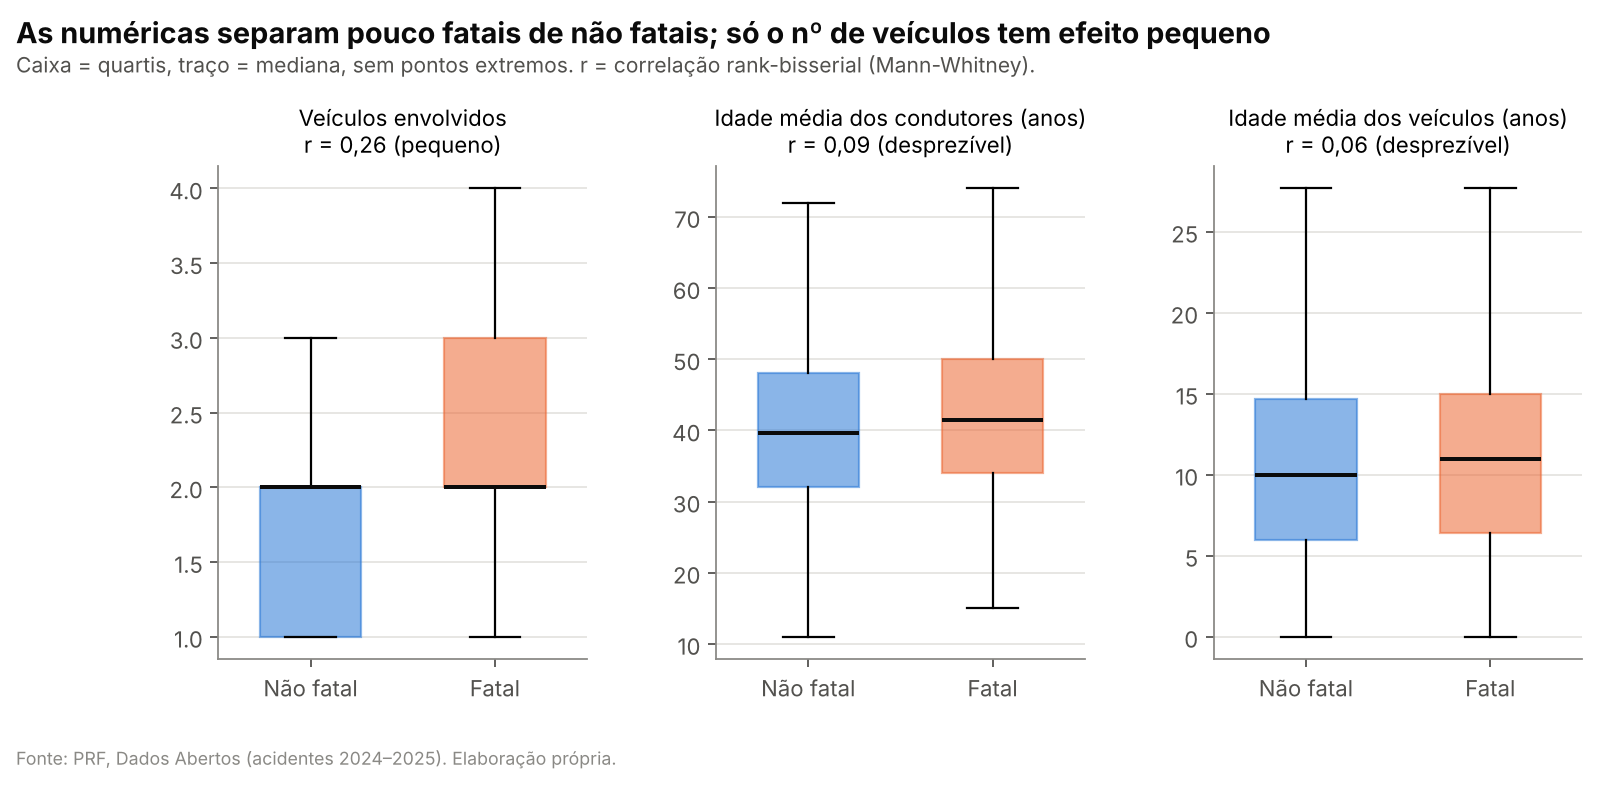

In [11]:
display(t["p2_testes_mann_whitney"][["variavel","mediana_fatal","mediana_nao_fatal","r_rank_bisserial","magnitude","p_holm"]].round(3))
display(Image(FIG / "p2_fig8_boxplots_numericas.png", width=900))

## 6. Causa raiz × confusão (Cochran-Mantel-Haenszel)
Se o RR ajustado ficar perto do bruto, o fator não é explicado pelo estrato.

,analise,rr_bruto,rr_ajustado_mh,rr_mh_ic_inf,rr_mh_ic_sup,pct_efeito_mantido,p_holm
0,"Noite/madrugada, controlando o tipo de pista",1.938,1.888,1.818,1.960,96.020,0.0
1,"Noite/madrugada, controlando trecho urbano/rural",1.938,1.907,1.837,1.980,97.582,0.0
2,"Pista simples, controlando trecho urbano/rural",2.160,1.958,1.878,2.042,87.275,0.0
3,"Norte/Nordeste, controlando o tipo de pista",1.905,1.739,1.670,1.811,85.833,0.0


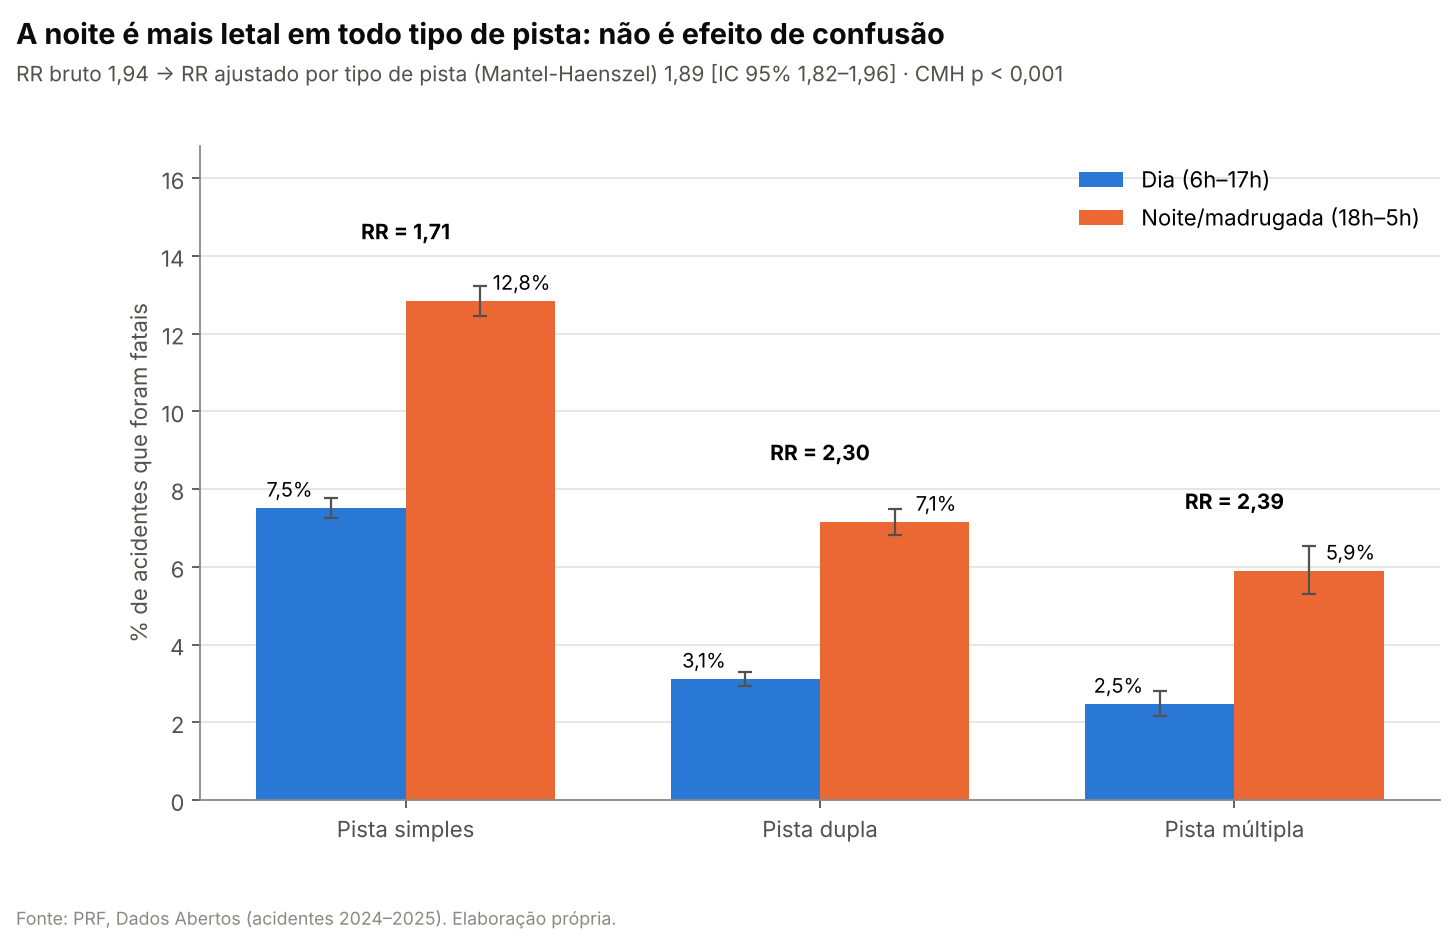

In [12]:
display(t["p2_estratificadas_resumo"][["analise","rr_bruto","rr_ajustado_mh","rr_mh_ic_inf","rr_mh_ic_sup","pct_efeito_mantido","p_holm"]].round(3))
display(Image(FIG / "p2_fig4_estratificada_noite_pista.png", width=850))

## 7. Veredito das hipóteses

In [13]:
t["p2_veredito_hipoteses"][["hipotese","enunciado","veredito"]]

,hipotese,enunciado,veredito
0,H1,Acidentes de madrugada e à noite são mais leta...,confirmada
1,H2,"Pista simples, trecho rural e curva elevam a l...",confirmada
2,H3,"Pedestres, ciclistas, motociclistas e veículos...",parcial
3,H4,Norte e Nordeste têm letalidade maior do que S...,confirmada
4,H5,Fins de semana e feriados são mais letais.,parcial
5,H6,"Tempo ruim (chuva, neblina) eleva a letalidade.",rejeitada (efeito oposto)
6,H7,A causa e o tipo do acidente mudam muito a let...,confirmada
7,H8,"Idade dos condutores, idade dos veículos e nº ...",parcial
8,H9,Há sazonalidade mensal na letalidade.,"significativa, efeito desprezível"


## 8. Para a Pessoa 3: associação de cada atributo com o alvo (mesma régua)

In [14]:
t["p2_ranking_atributos"].head(15).round(3)

,posicao,atributo,v_cramer,magnitude,n_categorias_teste,observacao
0,1,tipo_acidente,0.305,médio,16,Pós-evento (definido pela PRF no atendimento):...
1,2,grupo_causa,0.178,pequeno,9,Pós-evento (definido pela PRF no atendimento):...
2,3,envolve_pedestre,0.173,pequeno,2,
3,4,veiculos,0.132,pequeno,9,
4,5,uf,0.121,pequeno,27,Alta cardinalidade (27): considerar target enc...
5,6,envolve_caminhao,0.119,pequeno,2,
6,7,br,0.114,pequeno,65,Alta cardinalidade: target encoding dentro do ...
7,8,tipo_pista,0.103,pequeno,3,
8,9,hora,0.102,pequeno,24,Relação não linear (pico na madrugada): usar f...
9,10,fase_dia,0.098,desprezível,4,Redundante com faixa_horaria/hora; escolher um...


## Conclusões
1. **Quando:** 18h–5h, sobretudo fim de semana (RR ≈ 1,9; ~57% das mortes).
2. **Onde:** pista simples, trecho rural, curva, Norte/Nordeste (RR ≈ 2); colisão frontal em pista simples ≈ 26% das mortes.
3. **Quem:** pedestre (RR ≈ 4,6), caminhão (RR ≈ 2,3).
4. **Derrubadas:** moto, chuva e feriado não aumentam a letalidade por acidente; sazonalidade mensal desprezível.
5. Efeitos sobrevivem à estratificação e se repetem em 2024 e 2025 → base sólida para os insights (Pessoa 4).